<a href="https://colab.research.google.com/github/lakshyakhanna17/Est_Project/blob/main/Copy_of_Biocon_Malaria_Detection_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Automated Malaria Detection from Red Blood Cell Images using a CNN

## Overview
Biocon Ltd. wants to speed up the diagnosis of blood samples by using automation. In this project I build a Convolutional Neural Network (CNN) that looks at the image of a single red blood cell and decides whether the cell is healthy (uninfected) or infected with the malaria parasite (parasitized). Apart from training the model, I check how reliable it is, explain its decisions with Grad-CAM, make it smaller with quantization and build a small demo app.

## Contents
- Problem understanding
- Project pipeline
- Setting up the environment
- Dataset and exploratory data analysis
- Data preprocessing and feature engineering
- Model design and justification
- Model training and hyperparameter tuning
- Model evaluation, threshold analysis and error analysis
- Explainable AI (Grad-CAM)
- Model optimization (quantization)
- Deployment readiness and ethics
- Demo and application
- Conclusion, limitations and references

## Problem Understanding

**Domain.** Malaria is caused by Plasmodium parasites that infect red blood cells and is spread by mosquitoes. It is still a serious health problem in many parts of the world. The standard test is that a trained technician looks at a stained blood smear under a microscope and searches for parasites inside the cells. This takes time, needs experienced staff, and the result can differ from person to person, especially when the parasites are small or the stain is faint.

**Why automation helps.** If a computer screens the cell images first, technicians can spend their time on the doubtful cases and the results come faster. This matches the Biocon scenario of faster and more accurate diagnostics.

**Objective.** Build a CNN that classifies a red blood cell image as healthy (uninfected) or malaria-infected (parasitized).

**How I measure success.** Accuracy alone is not enough here. A missed infection (false negative) is more dangerous than a false alarm (false positive), so I focus on recall for the infected class, together with precision, F1-score, the confusion matrix and ROC-AUC.

**Scope.** The model works on single, already cropped cell images. It is a learning project and a screening aid, not a certified diagnostic tool.

## Project Pipeline

The diagram below shows the five stages of this project: define the problem, collect the data, process the data, build the model and evaluate it. The rest of the notebook follows the same order. The figure is also saved as a PNG file so that it can be used in the presentation.

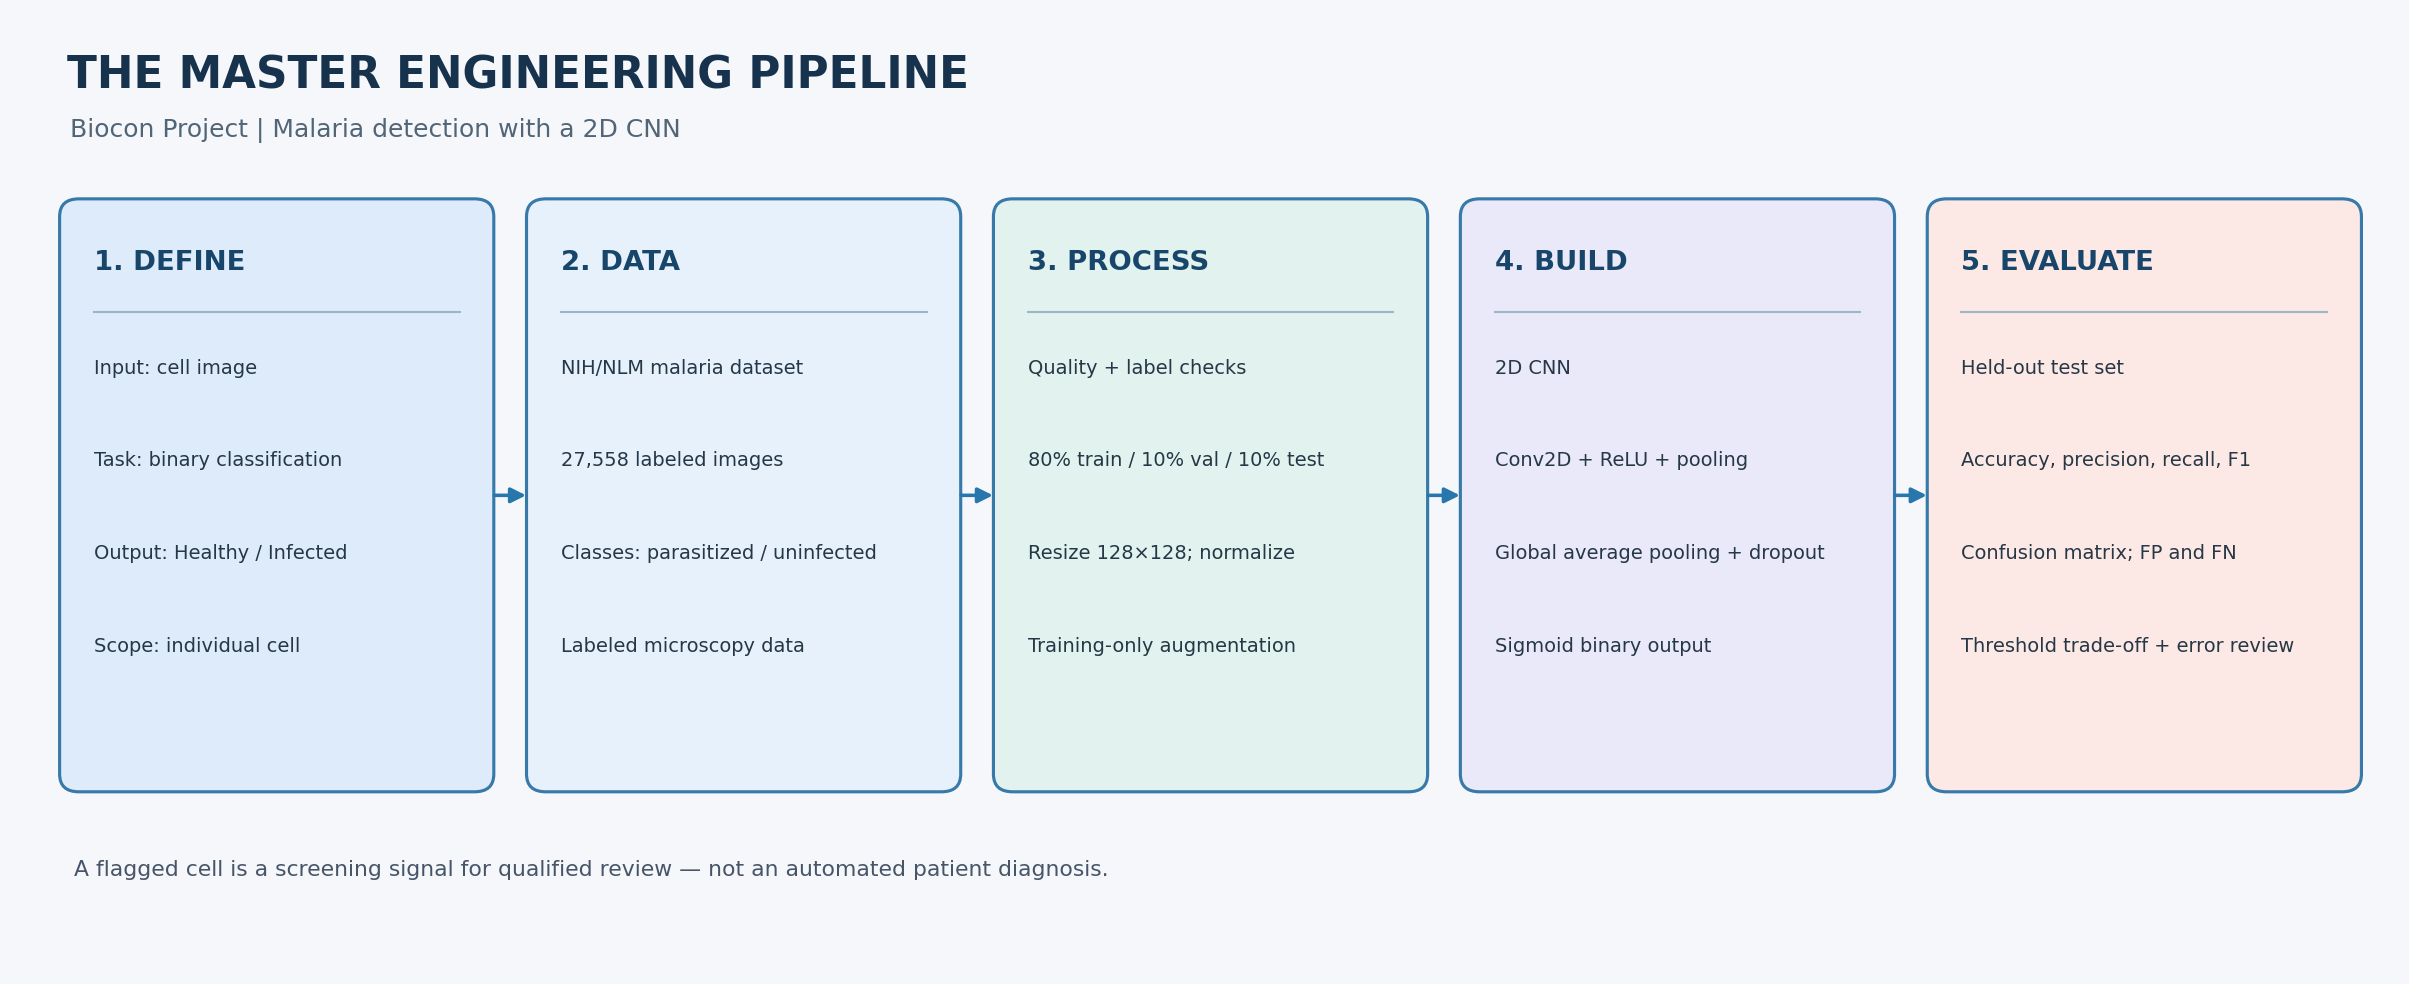

In [ ]:
# Required course artifact: generate and display the five-stage Master Engineering Pipeline.
# The PNG is saved to the Colab working folder so it can be included in a report/presentation.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 6.5), dpi=150)
fig.patch.set_facecolor('#F5F7FA')
ax.set_facecolor('#F5F7FA')
ax.set_xlim(0, 16)
ax.set_ylim(0, 7)
ax.axis('off')
ax.text(0.35, 6.55, 'THE MASTER ENGINEERING PIPELINE', fontsize=21, fontweight='bold', color='#17324D', va='center')
ax.text(0.37, 6.15, 'Biocon Project | Malaria detection with a 2D CNN', fontsize=12, color='#526577', va='center')

stages = [
    ('1. DEFINE', 'Input: cell image', 'Task: binary classification', 'Output: Healthy / Infected', 'Scope: individual cell', '#DDEBFA'),
    ('2. DATA', 'NIH/NLM malaria dataset', '27,558 labeled images', 'Classes: parasitized / uninfected', 'Labeled microscopy data', '#E6F1FC'),
    ('3. PROCESS', 'Quality + label checks', '80% train / 10% val / 10% test', 'Resize 128×128; normalize', 'Training-only augmentation', '#E2F2EF'),
    ('4. BUILD', '2D CNN', 'Conv2D + ReLU + pooling', 'Global average pooling + dropout', 'Sigmoid binary output', '#E9E9FA'),
    ('5. EVALUATE', 'Held-out test set', 'Accuracy, precision, recall, F1', 'Confusion matrix; FP and FN', 'Threshold trade-off + error review', '#FCE9E5'),
]
start_x, w, gap, y, h = 0.35, 2.82, 0.32, 1.35, 4.25
for i, (title, a, b, c, d, color) in enumerate(stages):
    x = start_x + i * (w + gap)
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.13', linewidth=1.5, edgecolor='#3779A8', facecolor=color)
    ax.add_patch(box)
    ax.text(x+0.18, y+h-0.42, title, fontsize=13.2, fontweight='bold', color='#17466A', va='center')
    ax.plot([x+0.18, x+w-0.18], [y+h-0.78, y+h-0.78], color='#9CB6C8', linewidth=1)
    lines_here = [a, b, c, d]
    yy = y+h-1.12
    for line in lines_here:
        ax.text(x+0.18, yy, line, fontsize=9.3, color='#263746', va='top', wrap=True)
        yy -= 0.68
    if i < len(stages)-1:
        ax.add_patch(FancyArrowPatch((x+w+0.025, y+h/2), (x+w+gap-0.025, y+h/2), arrowstyle='-|>', mutation_scale=15, linewidth=1.7, color='#2877AC'))
ax.text(0.4, 0.73, 'A flagged cell is a screening signal for qualified review — not an automated patient diagnosis.', fontsize=10.5, color='#475569', va='center')
fig.tight_layout(pad=0.5)
fig.savefig('biocon_malaria_master_pipeline.png', dpi=180, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()

In [ ]:
%pip -q install tensorflow-datasets scikit-learn importlib-resources plotly

## Setting Up the Environment

I ran this notebook on Google Colab with a GPU. After installing the extra packages in the cell above, I import the libraries I need: TensorFlow and Keras for the model, TensorFlow Datasets to load the data, NumPy and pandas for data handling, Matplotlib and Plotly for graphs, and scikit-learn for the evaluation metrics. I also set a random seed (42) so that the results are as repeatable as possible.


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: True


## Dataset

I used the malaria dataset from the National Institutes of Health (NIH / NLM), which is available through TensorFlow Datasets. It has 27,558 images of single red blood cells taken from thin blood smear slides. Each image has one label:
- 0 = parasitized (infected)
- 1 = uninfected (healthy)

Every image is cropped to one cell, with a black background around it. The dataset comes as one block, so I split it myself into 80% training (22,046 images), 10% validation (2,756 images) and 10% test (2,756 images). The test set is not used during training or tuning, only for the final evaluation.

In [ ]:
(raw_train, raw_val, raw_test), info = tfds.load(
    "malaria",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True,
    with_info=True,
)

class_names = info.features["label"].names
print("Class label mapping:")
for index, name in enumerate(class_names):
    print(f"  {index} -> {name}")
print("Total images:", info.splits["train"].num_examples)
print("Training examples:", int(info.splits["train"].num_examples * 0.8))
print("Validation and test are each approximately 10%.")

Class label mapping:
  0 -> parasitized
  1 -> uninfected
Total images: 27558
Training examples: 22046
Validation and test are each approximately 10%.


## Exploratory Data Analysis (EDA)

Before building the model, I wanted to understand the data. First I counted the images of each class in the three splits. If one class had many more images than the other, a model could look accurate just by always guessing the bigger class, and I would have to handle that imbalance. After that I checked the size and the average colour of the images.

,parasitized,uninfected,Total
Train,10999,11047,22046
Validation,1409,1347,2756
Test,1371,1385,2756


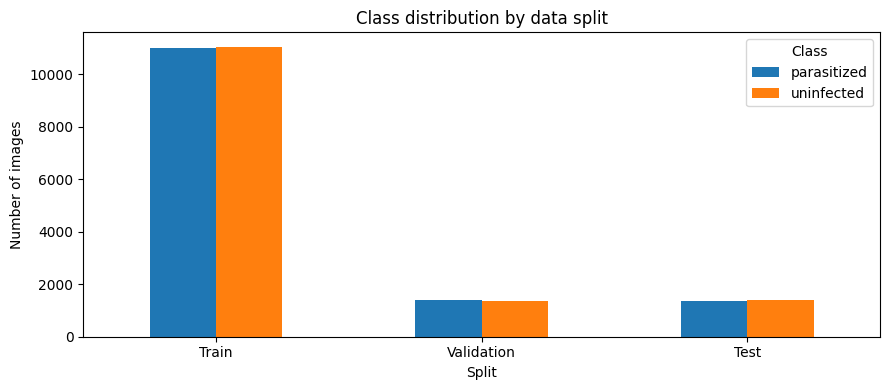

EDA insight:
Train — parasitized: 10999 (49.9%), uninfected: 11047 (50.1%)
Validation — parasitized: 1409 (51.1%), uninfected: 1347 (48.9%)
Test — parasitized: 1371 (49.7%), uninfected: 1385 (50.3%)


In [ ]:
def count_split_labels(dataset, number_of_classes):
    counts = np.zeros(number_of_classes, dtype=np.int64)
    # Map away the image tensor and process labels in batches.
    label_batches = dataset.map(lambda image, label: label).batch(1024)
    for batch_labels in label_batches.as_numpy_iterator():
        counts += np.bincount(np.asarray(batch_labels).astype(int).reshape(-1), minlength=number_of_classes)
    return counts

split_counts = {
    "Train": count_split_labels(raw_train, len(class_names)),
    "Validation": count_split_labels(raw_val, len(class_names)),
    "Test": count_split_labels(raw_test, len(class_names)),
}
class_distribution = pd.DataFrame(split_counts, index=class_names).T
class_distribution["Total"] = class_distribution.sum(axis=1)
display(class_distribution)

ax = class_distribution[class_names].plot(kind="bar", figsize=(9, 4), rot=0)
ax.set_title("Class distribution by data split")
ax.set_xlabel("Split")
ax.set_ylabel("Number of images")
ax.legend(title="Class")
plt.tight_layout()
plt.show()

print("EDA insight:")
for split_name, row in class_distribution.iterrows():
    total = int(row["Total"])
    pieces = [f"{name}: {int(row[name])} ({row[name] / total:.1%})" for name in class_names]
    print(f"{split_name} — " + ", ".join(pieces))

Height: min 70, median 133, max 262
Width:  min 46, median 130, max 250


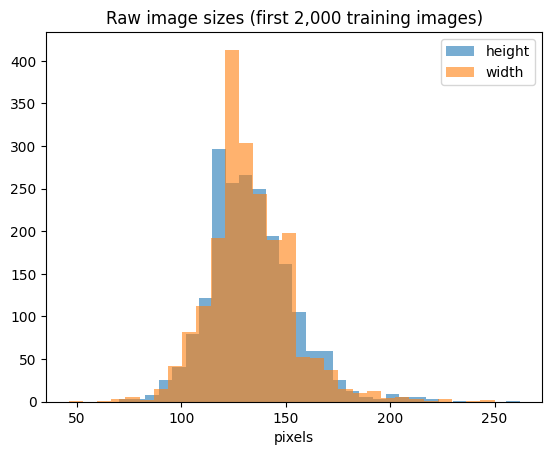

,R,G,B
parasitized,133.6,103.4,111.6
uninfected,134.9,113.3,119.8


In [ ]:
sizes, mean_rgb = [], {name: [] for name in class_names}
for image, label in raw_train.take(2000):
    h, w, _ = image.shape
    sizes.append((h, w))
    mean_rgb[class_names[int(label)]].append(image.numpy().reshape(-1, 3).mean(axis=0))
sizes = np.array(sizes)
print(f"Height: min {sizes[:,0].min()}, median {int(np.median(sizes[:,0]))}, max {sizes[:,0].max()}")
print(f"Width:  min {sizes[:,1].min()}, median {int(np.median(sizes[:,1]))}, max {sizes[:,1].max()}")
plt.hist(sizes[:,0], bins=30, alpha=.6, label="height"); plt.hist(sizes[:,1], bins=30, alpha=.6, label="width")
plt.title("Raw image sizes (first 2,000 training images)"); plt.xlabel("pixels"); plt.legend(); plt.show()
display(pd.DataFrame({n: np.mean(v, axis=0) for n, v in mean_rgb.items()}, index=["R", "G", "B"]).T.round(1))

### EDA Insights

- **Class balance:** The data is almost perfectly balanced. Parasitized cells are 49.9% of the training set, 51.1% of the validation set and 49.7% of the test set. So I do not need class weights or resampling, and accuracy is a fair metric. I still report recall and precision for the infected class.
- **Image size:** The images are not all the same size. Heights go from 70 to 262 pixels and widths from 46 to 250 pixels (the median is about 133 high and 130 wide, measured on the first 2,000 training images). A CNN needs a fixed input size, so all images must be resized.
- **Colour:** On average, infected cells have lower green and blue values than healthy cells (about 103 and 112 compared with 113 and 120). The averages include the black background, so I only use them for comparison. The difference is probably caused by the dark stain on the parasite, which tells me that colour carries useful information, so I keep the images in RGB and do not convert them to grayscale.

### Data Quality Check

All checks passed for the 64 sampled training images. This confirms that the sampled images were non-empty, had three RGB channels and contained valid labels. A full-dataset check would be needed to confirm these properties for every image.

In [ ]:
checked = 0
for image, label in raw_train.take(64):
    image_array = image.numpy()
    label_value = int(label.numpy())
    assert image_array.size > 0, 'Empty image encountered'
    assert image_array.ndim == 3 and image_array.shape[-1] == 3, f'Expected RGB image, got {image_array.shape}'
    assert 0 <= label_value < len(class_names), f'Invalid class label: {label_value}'
    checked += 1
print(f'Data sanity check passed for {checked} sample images.')

Data sanity check passed for 64 sample images.


### Looking at Sample Images

Numbers do not show everything, so I plotted some random training images with their labels. Healthy cells usually look smooth and evenly coloured, while infected cells usually have one or more dark purple spots or rings, which are the parasites. The cells also differ in shape, size and stain colour, and some infected cells have only a very small spot. This shows me that the task is not trivial and that the model must be able to pick up small details.

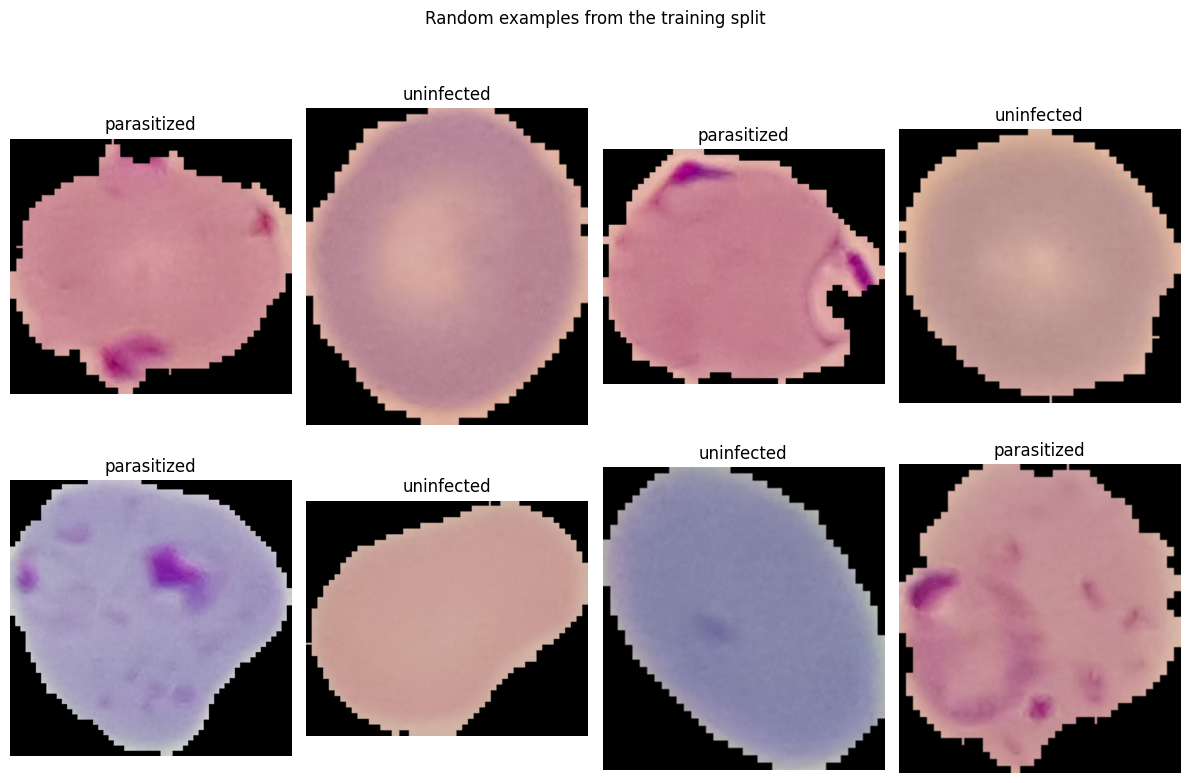

In [ ]:
plt.figure(figsize=(12, 8))
for i, (image, label) in enumerate(raw_train.shuffle(256, seed=SEED).take(8)):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[int(label.numpy())])
    plt.axis("off")
plt.suptitle("Random examples from the training split", y=1.02)
plt.tight_layout()
plt.show()

## Data Preprocessing and Feature Engineering

**Resizing.** All images are resized to 128 × 128 pixels so that they can be given to the CNN in batches. I chose 128 because the small parasite details are still visible and the training stays fast.

**Batching and shuffling.** The training data is shuffled in every epoch and grouped into batches of 32. Prefetching is used so that the GPU does not wait for data. The labels are reshaped to match the single output of the model.

**Normalisation.** The pixel values (0 to 255) are scaled to the range 0 to 1 with a Rescaling layer inside the model. Because the scaling is part of the model, the same scaling is applied automatically when I use the model on new images.

**Data augmentation.** Random horizontal and vertical flips and random rotations are applied to the training images only. A blood cell has no fixed direction, so these changes make realistic new versions of the images and help the model to generalise instead of memorising. The validation and test images are not changed. Both augmentation and normalisation are placed inside the model, so they are defined in the model-building cell below.

**Feature engineering.** I did not extract features by hand, such as colour histograms or shape measurements. A CNN learns its features directly from the pixels, from simple edges and colours in the first layers to more complex shapes, like the parasite, in the deeper layers. My own decisions were to keep the RGB colour channels (because of the EDA result) and to use the augmentation above.

**Data splitting.** The 80 / 10 / 10 split into training, validation and test sets was done when loading the dataset.

In [ ]:
IMAGE_SIZE = 128
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def resize_image(image, label):
    image = tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
    label = tf.cast(label, tf.float32)
    label = tf.expand_dims(label, axis=-1)  # shape (1,) per image, matching model output
    return image, label

train_ds = (
    raw_train
    .shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    .map(resize_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    raw_val
    .map(resize_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    raw_test
    .map(resize_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

for image_batch, label_batch in train_ds.take(1):
    print("Image batch shape:", image_batch.shape)  # (batch, 128, 128, 3)
    print("Label batch shape:", label_batch.shape)  # (batch, 1)

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32, 1)


## Model Design and Justification

**Why a CNN?** The input is an image, and what matters is a local pattern such as the colour and shape of a stained spot. A CNN is made for this. Its filters slide over the image and look for the same pattern at every position, and it needs far fewer parameters than a fully connected network working on raw pixels. CNNs are also a standard choice for medical image classification.

**Architecture.** I built a small CNN from scratch:
- A Rescaling layer, followed by random flip and rotation layers (augmentation, active only during training).
- Three convolution blocks with 32, 64 and 128 filters of size 3 × 3 and ReLU activation. Each block ends with max pooling, which halves the image size and keeps the strongest responses. The number of filters grows in each block because the deeper layers have to learn more complex patterns.
- A Global Average Pooling layer, which turns every feature map into one number. I used it instead of Flatten because it needs far fewer parameters, which lowers the risk of overfitting.
- A Dense layer with 64 units and ReLU, followed by Dropout of 0.3, which switches off 30% of the units randomly during training to reduce overfitting.
- A final Dense layer with one unit and sigmoid activation. It gives a value between 0 and 1 for label 1 (uninfected), so the model is a binary classifier.

**Why this size?** The model has only about 101,569 parameters (roughly 0.4 MB). The dataset is not huge and there are only two classes, so a big network is not needed. A small model trains quickly, is less likely to overfit and can run on cheap devices, which matters for use in a lab or a clinic.

**Loss and optimizer.** I use binary cross-entropy as the loss, because it suits a two-class problem with a sigmoid output, and the Adam optimizer with a learning rate of 0.001. One epoch means that the model has seen the whole training set once. The summary below lists all layers and the number of parameters.

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),

    # Pixel normalization: 0–255 becomes 0–1.
    tf.keras.layers.Rescaling(1.0 / 255),

    # Data augmentation is active during training only.
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.25),

    # Learn visual features.
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # Turn feature maps into a compact representation.
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.30),

    # Binary classifier: score for class label 1.
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

## Model Training

The model is trained for up to 25 epochs on the training set, and the validation set is used to watch its progress. I used two callbacks. EarlyStopping stops the training if the validation loss does not improve for 4 epochs and then restores the weights of the best epoch. TerminateOnNaN stops the training if the loss becomes invalid. With this I did not need to guess the exact number of epochs, and the final model is the one with the best validation loss, not just the one from the last epoch.

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.TerminateOnNaN(),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks,
)


Epoch 1/25
689/689 ━━━━━━━━━━━━━━━━━━━━ 29s 33ms/step - accuracy: 0.8049 - loss: 0.4321 - val_accuracy: 0.9311 - val_loss: 0.2132
Epoch 2/25
689/689 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.9297 - loss: 0.2192 - val_accuracy: 0.9405 - val_loss: 0.1755
Epoch 3/25
689/689 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.9405 - loss: 0.1854 - val_accuracy: 0.9510 - val_loss: 0.1670
Epoch 4/25
689/689 ━━━━━━━━━━━━━━━━━━━━ 41s 32ms/step - accuracy: 0.9496 - loss: 0.1681 - val_accuracy: 0.9456 - val_loss: 0.1799
Epoch 5/25
689/689 ━━━━━━━━━━━━━━━━━━━━ 41s 32ms/step - accuracy: 0.9499 - loss: 0.1593 - val_accuracy: 0.9543 - val_loss: 0.1477
Epoch 6/25
689/689 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.9521 - loss: 0.1509 - val_accuracy: 0.9528 - val_loss: 0.1473
Epoch 7/25
689/689 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.9529 - loss: 0.1472 - val_accuracy: 0.9481 - val_loss: 0.1555
Epoch 8/25
689/689 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.9547 - loss: 0.1459 - 

### Learning Curves

These graphs show the accuracy and the loss of every epoch for the training and the validation data.The training and validation curves remain relatively close, suggesting that there is no obvious large gap between training and validation performance. However, these curves alone cannot rule out overfitting or data leakage between images from the same patient. The loss falls quickly in the first epochs and then becomes flat, and the accuracy settles at about 96%. The best validation loss was reached at epoch 22. Because the curves are flat at the end, more epochs would probably give very little improvement with this architecture.

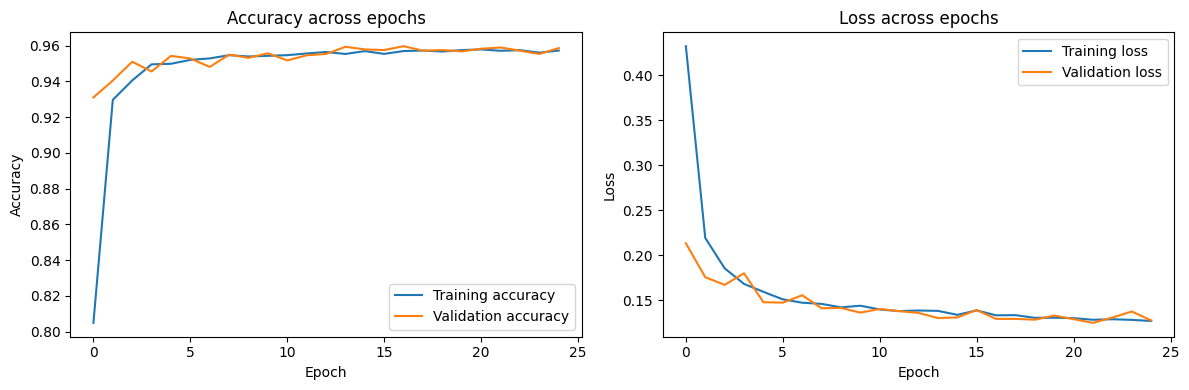

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy across epochs")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss across epochs")
plt.legend()

plt.tight_layout()
plt.show()

### Hyperparameter Tuning: Learning Rate

The learning rate decides how big the steps of the optimizer are. If it is too high the training can become unstable, and if it is too low the learning is slow. I compared 0.001 and 0.0003. Both models started from the same initial weights and were trained for 3 epochs, and I compared them on the validation loss, not on the test set, so that the test data is not used for tuning. The learning rate 0.001 gave the lower validation loss, so I kept it for the final model. The experiment was short (3 epochs only), so it is a quick comparison and not a full search. Other settings, such as dropout and the number of filters, could be tested in the future.

In [ ]:

# Compare two learning rates on validation data.
# This experiment does not overwrite the final model.

tf.keras.utils.set_random_seed(SEED)

template = tf.keras.models.clone_model(model)
_ = template(
    tf.zeros((1, IMAGE_SIZE, IMAGE_SIZE, 3)),
    training=False
)
initial_weights = template.get_weights()

tuning_results = []

for learning_rate in [0.001, 0.0003]:
    candidate = tf.keras.models.clone_model(model)
    _ = candidate(
        tf.zeros((1, IMAGE_SIZE, IMAGE_SIZE, 3)),
        training=False
    )
    candidate.set_weights(initial_weights)

    candidate.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    candidate_history = candidate.fit(
        train_ds,
        validation_data=val_ds,
        epochs=3,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=1,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    best_epoch = int(np.argmin(
        candidate_history.history["val_loss"]
    ))

    tuning_results.append({
        "learning_rate": learning_rate,
        "best_validation_loss":
            candidate_history.history["val_loss"][best_epoch],
        "validation_accuracy_at_best_loss":
            candidate_history.history["val_accuracy"][best_epoch]
    })

lr_comparison = pd.DataFrame(tuning_results)
display(lr_comparison.round(4))


Epoch 1/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.7721 - loss: 0.4688 - val_accuracy: 0.9253 - val_loss: 0.2360
Epoch 2/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - accuracy: 0.9313 - loss: 0.2309 - val_accuracy: 0.9445 - val_loss: 0.1786
Epoch 3/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 40s 30ms/step - accuracy: 0.9350 - loss: 0.2016 - val_accuracy: 0.9452 - val_loss: 0.1813
Epoch 1/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 25s 31ms/step - accuracy: 0.6568 - loss: 0.6234 - val_accuracy: 0.8367 - val_loss: 0.4851
Epoch 2/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.8888 - loss: 0.3348 - val_accuracy: 0.9256 - val_loss: 0.2267
Epoch 3/3
689/689 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.9196 - loss: 0.2554 - val_accuracy: 0.9242 - val_loss: 0.2152


,learning_rate,best_validation_loss,validation_accuracy_at_best_loss
0,0.0010,0.1786,0.9445
1,0.0003,0.2152,0.9242


## Model Evaluation

The final model is evaluated on the test set, which it never saw during training or tuning. In medical tasks accuracy alone can hide problems, so I also use these measures for the infected class:
- **Precision:** of all the cells that the model calls infected, how many are really infected.
- **Recall (sensitivity):** of all the really infected cells, how many the model finds. This is the most important measure here, because a missed infection is the worst kind of error.
- **F1-score:** the balance between precision and recall.
- **Confusion matrix:** shows how many cells of each class were classified correctly and wrongly.
- **ROC curve and AUC:** show how well the model separates the two classes at all possible thresholds. An AUC close to 1 means a very good separation.

87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9637 - loss: 0.1287

Test loss: 0.1287
Test accuracy: 0.9637
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step

Classification report:
              precision    recall  f1-score   support

 parasitized       0.97      0.95      0.96      1371
  uninfected       0.95      0.97      0.96      1385

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756



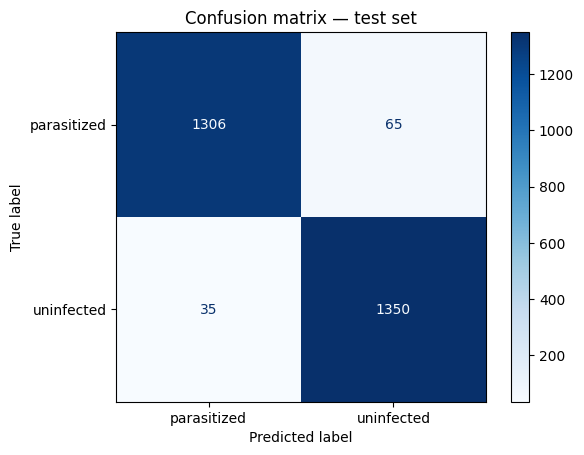

Infected-class recall: 0.9526
Infected-class precision: 0.9739


In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

# Test data is not shuffled, so these labels stay in the same order as predictions.
y_true = np.concatenate([labels.numpy().astype(int) for _, labels in test_ds]).ravel()
prob_label1 = model.predict(test_ds, verbose=1).ravel()
y_pred = (prob_label1 >= 0.5).astype(int)

print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
cm_display.plot(values_format="d", cmap="Blues")
plt.title("Confusion matrix — test set")
plt.show()

infected_idx = next(
    (i for i, name in enumerate(class_names)
     if any(term in name.lower() for term in ["parasitized", "infected", "malaria"])),
    None,
)
if infected_idx is not None:
    print("Infected-class recall:", round(recall_score(y_true, y_pred, pos_label=infected_idx, zero_division=0), 4))
    print("Infected-class precision:", round(precision_score(y_true, y_pred, pos_label=infected_idx, zero_division=0), 4))


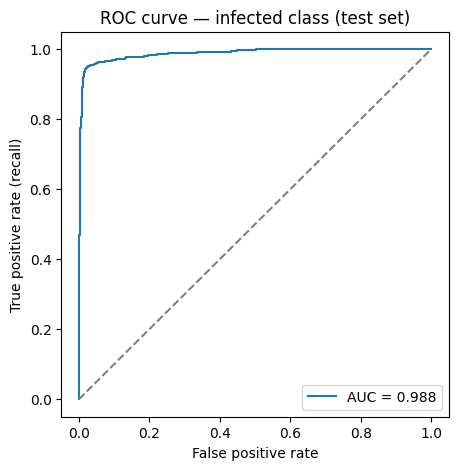

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
y_inf = (y_true == infected_idx).astype(int)
score_inf = prob_label1 if infected_idx == 1 else 1.0 - prob_label1
auc = roc_auc_score(y_inf, score_inf)
fpr, tpr, _ = roc_curve(y_inf, score_inf)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}"); plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curve — infected class (test set)"); plt.legend(); plt.show()

### False Positives and False Negatives

In this project a false negative is an infected cell that the model calls healthy, so an infection could be missed. A false positive is a healthy cell that the model calls infected, which gives a false alarm and an unnecessary extra check. Both are counted below at the default threshold of 0.5. For a screening tool, false negatives are the more serious problem, so I want to keep them as low as possible without letting the false alarms grow too much.

In [ ]:
# Error counts at the default 0.5 cutoff.
# infected_idx, y_true and y_pred come from the evaluation cell above.
healthy_idx = 1 - infected_idx
TP = int(np.sum((y_true == infected_idx) & (y_pred == infected_idx)))
FN = int(np.sum((y_true == infected_idx) & (y_pred == healthy_idx)))
FP = int(np.sum((y_true == healthy_idx) & (y_pred == infected_idx)))
TN = int(np.sum((y_true == healthy_idx) & (y_pred == healthy_idx)))

print('Baseline test cutoff: 0.50')
print(f'True positives (infected correctly flagged): {TP}')
print(f'False negatives (infected predicted uninfected): {FN}')
print(f'False positives (uninfected predicted infected): {FP}')
print(f'True negatives (uninfected correctly not flagged): {TN}')
print(f'Total incorrect predictions: {FN + FP} out of {len(y_true)}')
print('\nInterpretation: FN represents missed infection signals; FP represents false alarms.')

Baseline test cutoff: 0.50
True positives (infected correctly flagged): 1306
False negatives (infected predicted uninfected): 65
False positives (uninfected predicted infected): 35
True negatives (uninfected correctly not flagged): 1350
Total incorrect predictions: 100 out of 2756

Interpretation: FN represents missed infection signals; FP represents false alarms.


In [ ]:
from IPython.display import Markdown
rec = recall_score(y_true, y_pred, pos_label=infected_idx)
prec = precision_score(y_true, y_pred, pos_label=infected_idx)
display(Markdown(f"**Final test results (cutoff 0.50):** accuracy {test_accuracy:.2%} · infected recall {rec:.2%} · "
                  f"infected precision {prec:.2%} · FN {FN} · FP {FP} · ROC-AUC {auc:.3f}"))

**Final test results (cutoff 0.50):** accuracy 96.37% · infected recall 95.26% · infected precision 97.39% · FN 65 · FP 35 · ROC-AUC 0.988

### Threshold Analysis

The model gives a score between 0 and 1, and by default a cell is called infected when its infected score is at least 0.5. Changing this threshold changes the balance between false negatives and false positives. A lower threshold finds more infections but gives more false alarms, and a higher threshold does the opposite. I tested thresholds from 0.10 to 0.90 on the validation set and chose the one with the best precision among those that keep the validation recall at 95% or more. The 95% target is only my own choice for this comparison and not a clinical standard. The chosen threshold was then checked once on the test set. The results at 0.5 remain my main results, and this is a secondary experiment.

In [ ]:
# Identify which numeric label is infected; don't assume it is label 1.
infected_idx = next(
    (i for i, name in enumerate(class_names)
     if any(term in name.lower() for term in ['parasitized', 'infected', 'malaria'])),
    None,
)
if infected_idx is None:
    raise ValueError(f'Could not identify infected class in {class_names}')
healthy_idx = 1 - infected_idx

# Validation labels and sigmoid scores for class label 1.
val_y = np.concatenate([labels.numpy().astype(int).reshape(-1) for _, labels in val_ds])
val_score_label1 = model.predict(val_ds, verbose=0).reshape(-1)
val_score_infected = val_score_label1 if infected_idx == 1 else 1.0 - val_score_label1
val_actual_infected = (val_y == infected_idx).astype(int)

threshold_results = []
for threshold in np.round(np.arange(0.10, 0.901, 0.05), 2):
    val_pred_infected = (val_score_infected >= threshold).astype(int)
    tn_v, fp_v, fn_v, tp_v = confusion_matrix(val_actual_infected, val_pred_infected, labels=[0, 1]).ravel()
    precision_v = precision_score(val_actual_infected, val_pred_infected, zero_division=0)
    recall_v = recall_score(val_actual_infected, val_pred_infected, zero_division=0)
    specificity_v = tn_v / (tn_v + fp_v) if (tn_v + fp_v) else 0.0
    f1_v = f1_score(val_actual_infected, val_pred_infected, zero_division=0)
    threshold_results.append({
        'threshold': float(threshold),
        'accuracy': accuracy_score(val_actual_infected, val_pred_infected),
        'infected_precision': precision_v,
        'infected_recall': recall_v,
        'specificity': specificity_v,
        'infected_f1': f1_v,
        'false_positives': int(fp_v),
        'false_negatives': int(fn_v),
    })

threshold_table = pd.DataFrame(threshold_results)
print(threshold_table.round(3).to_string(index=False))

TARGET_VALIDATION_RECALL = 0.95  # Educational comparison target only; not a clinical standard.
eligible = threshold_table[threshold_table['infected_recall'] >= TARGET_VALIDATION_RECALL]
if len(eligible):
    chosen_row = eligible.sort_values(['infected_precision', 'infected_f1'], ascending=False).iloc[0]
    reason = f'best precision among thresholds with validation recall >= {TARGET_VALIDATION_RECALL:.0%}'
else:
    chosen_row = threshold_table.sort_values(['infected_recall', 'infected_precision'], ascending=False).iloc[0]
    reason = 'highest observed validation recall (the target was not reached)'
CHOSEN_THRESHOLD = float(chosen_row['threshold'])
print(f'Chosen demonstration threshold: {CHOSEN_THRESHOLD:.2f}')
print('Selection reason:', reason)

# Secondary evaluation on the test set. The threshold was selected using validation data, not test labels.
test_score_infected = prob_label1 if infected_idx == 1 else 1.0 - prob_label1
test_actual_infected = (y_true == infected_idx).astype(int)
test_pred_infected = (test_score_infected >= CHOSEN_THRESHOLD).astype(int)
tn_t, fp_t, fn_t, tp_t = confusion_matrix(test_actual_infected, test_pred_infected, labels=[0, 1]).ravel()
selected_y_pred = np.where(test_pred_infected == 1, infected_idx, healthy_idx)
precision_t = precision_score(test_actual_infected, test_pred_infected, zero_division=0)
recall_t = recall_score(test_actual_infected, test_pred_infected, zero_division=0)
specificity_t = tn_t / (tn_t + fp_t) if (tn_t + fp_t) else 0.0
f1_t = f1_score(test_actual_infected, test_pred_infected, zero_division=0)
print('\nSECONDARY HELD-OUT TEST RESULTS at the validation-selected cutoff')
print(f'Test accuracy: {accuracy_score(y_true, selected_y_pred):.4f}')
print(f'Infected precision: {precision_t:.4f}')
print(f'Infected recall/sensitivity: {recall_t:.4f}')
print(f'Specificity: {specificity_t:.4f}')
print(f'Infected F1-score: {f1_t:.4f}')
print(f'TP={tp_t}, FN={fn_t}, FP={fp_t}, TN={tn_t}')
print('Report these as a secondary threshold experiment; the 0.50 results above remain the baseline..')

 threshold  accuracy  infected_precision  infected_recall  specificity  infected_f1  false_positives  false_negatives
      0.10     0.937               0.904            0.979        0.892        0.940              146               29
      0.15     0.949               0.933            0.969        0.927        0.951               98               43
      0.20     0.954               0.946            0.964        0.943        0.955               77               51
      0.25     0.956               0.955            0.960        0.952        0.958               64               56
      0.30     0.959               0.963            0.957        0.961        0.960               52               60
      0.35     0.960               0.966            0.956        0.964        0.961               48               62
      0.40     0.960               0.968            0.953        0.967        0.961               44               66
      0.45     0.959               0.971            0.94

### Error Analysis: Misclassified Images

To understand why the model makes mistakes, I looked at some test images that were classified wrongly. Most of the errors I saw were infected cells predicted as healthy, usually cells with a very small or faint parasite or a weak stain. A few healthy cells were flagged as infected, probably because of a dark stain spot or an artifact at the edge of the cell. Some wrong predictions have scores near the 0.5 boundary, but others are confidently wrong (an infected score of only a few percent), which shows that the model can miss faint parasites completely. These examples show that the model can make mistakes even when its predictions are confident. Such cases would require review by a qualified expert in any potential screening application.


Total baseline test errors: 100 out of 2756


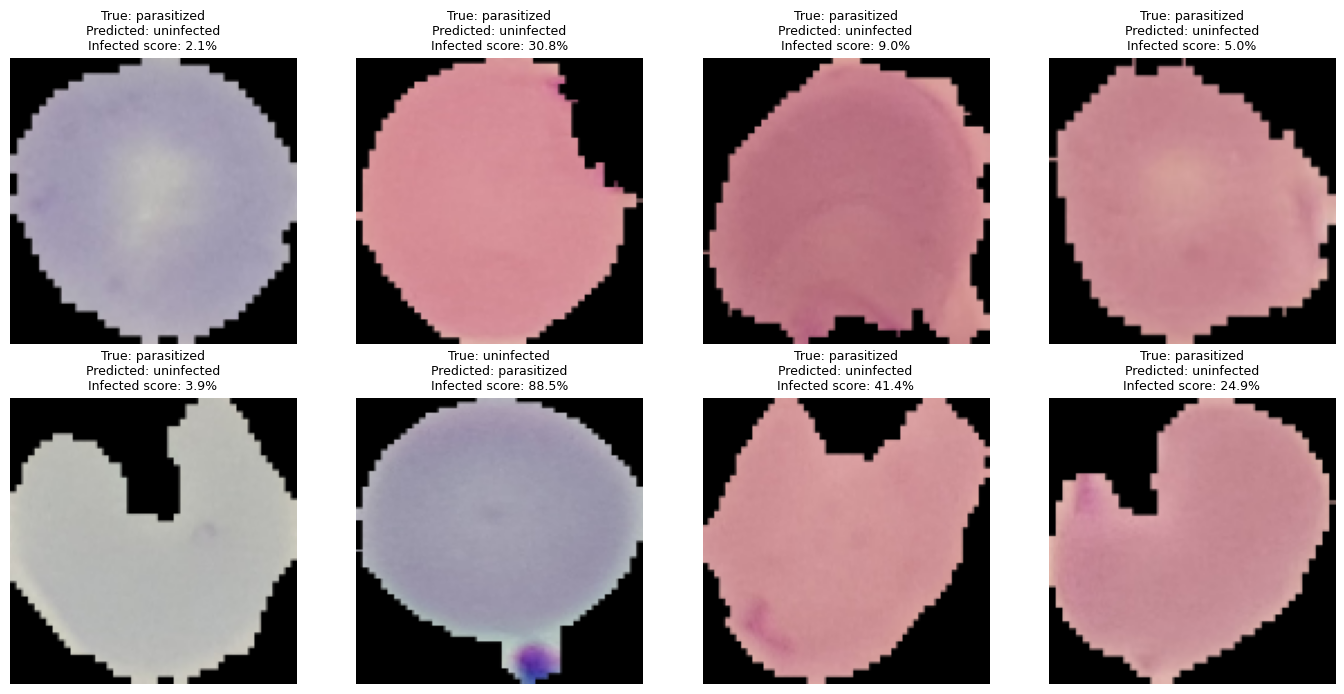

In [ ]:
wrong_examples = []
for image_batch, label_batch in test_ds:
    score_label1_batch = model.predict(image_batch, verbose=0).reshape(-1)
    true_batch = label_batch.numpy().astype(int).reshape(-1)
    pred_batch = (score_label1_batch >= 0.5).astype(int)
    score_infected_batch = score_label1_batch if infected_idx == 1 else 1.0 - score_label1_batch

    for j in range(len(true_batch)):
        if pred_batch[j] != true_batch[j]:
            wrong_examples.append((
                np.clip(image_batch[j].numpy(), 0, 255).astype(np.uint8),
                int(true_batch[j]), int(pred_batch[j]), float(score_infected_batch[j])
            ))
            if len(wrong_examples) >= 8:
                break
    if len(wrong_examples) >= 8:
        break

print(f'Total baseline test errors: {int(np.sum(y_true != y_pred))} out of {len(y_true)}')
if not wrong_examples:
    print('No errors were found in the inspected pass at the 0.50 cutoff.')
else:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.ravel()
    for ax, (img, true_idx, pred_idx, infected_score) in zip(axes, wrong_examples):
        ax.imshow(img)
        ax.set_title(
            f'True: {class_names[true_idx]}\nPredicted: {class_names[pred_idx]}\nInfected score: {infected_score:.1%}',
            fontsize=9,
        )
        ax.axis('off')
    for ax in axes[len(wrong_examples):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Saving the Model

The trained model is saved in the Keras format, so it can be loaded again later without training it again. This file also stores the optimizer state, so it is bigger than the weights alone.

In [ ]:
MODEL_PATH = "/content/malaria_cnn_model.keras"
model.save(MODEL_PATH)
print("Saved model to:", MODEL_PATH)
print("File size (MB):", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2))

Saved model to: /content/malaria_cnn_model.keras
File size (MB): 1.21


## Deployment Readiness and Application Insight

**Application potential.** The model can work as a first-pass screening tool in a pathology lab. It could go through the cell images of a slide and mark the suspicious cells, so that the technician only has to check the marked cells carefully. This can save time in busy labs and help places that have few trained microscopists.

**Deployment plan.**
1. A microscope camera captures the blood smear.
2. A segmentation step separates the single cells (the dataset I used already contains cropped cells, so this step is outside this project).
3. The CNN gives a score for every cell, and a slide is flagged if many cells are suspicious.
4. A lab technician or doctor reviews the flagged cells and takes the final decision.

The small FP16 TFLite model could be evaluated for deployment on a laptop or an edge device connected to a microscope. Actual compatibility and inference speed would need to be tested. The Gradio app below demonstrates what a simple interface could look like.

**Scalability.**

 The model has 101,569 parameters, requiring approximately 0.39 MiB of FP32 parameter storage. The saved Keras model is 1.21 MB, while the FP16 TensorFlow Lite model is approximately 0.20 MB. These results indicate a relatively small storage footprint. Inference speed and performance on edge devices have not been benchmarked in this project.”

**Ethical considerations.**
- The tool should support the doctor and not replace them. Every result must be confirmed by a qualified person and a standard test.
- False negatives are dangerous because an infected patient could be missed, so the threshold should favour recall and must be validated carefully.
- The data comes from a limited number of patients and one imaging setup. Stains, microscopes and patient groups in other places may be different, so the model must be tested on local data before use, and it may perform worse for some groups.
- Patient images are medical data, so privacy has to be protected with anonymised data, secure storage and access control.
- A real clinical tool needs approval from the health authorities and monitoring after deployment.

**Sensors and APIs.** I did not connect the model to a real sensor or live data source in this project. The Gradio app is a prototype interface that takes an uploaded image. In a real deployment, the same prediction function could be called from a microscope camera or from a hospital system through an API.

## Testing on Sample Images

To see the model in action, I took one healthy and one infected cell from the test set, which are images the model has never seen, and checked the prediction and the model score for each of them.

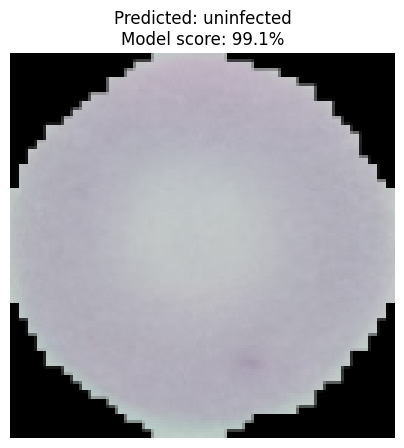

Actual class:    uninfected
Predicted class: uninfected
Model score:     99.1%
Prediction correct: True


In [ ]:
# Take one image from the unseen test dataset
images, labels = next(iter(test_ds))

sample_image = images[0]
actual_index = int(tf.reshape(labels[0], [-1])[0].numpy())

# Ask the trained CNN to predict the class
p_label1 = float(
    model.predict(tf.expand_dims(sample_image, axis=0), verbose=0)[0][0]
)

predicted_index = 1 if p_label1 >= 0.5 else 0

# Calculate the score for the predicted class
score = (
    p_label1
    if predicted_index == 1
    else 1 - p_label1
)

# Display the image and prediction
plt.figure(figsize=(5, 5))
plt.imshow(sample_image.numpy().astype("uint8"))
plt.axis("off")
plt.title(
    f"Predicted: {class_names[predicted_index]}\n"
    f"Model score: {score:.1%}"
)
plt.show()

print("Actual class:   ", class_names[actual_index])
print("Predicted class:", class_names[predicted_index])
print(f"Model score:     {score:.1%}")
print("Prediction correct:", actual_index == predicted_index)

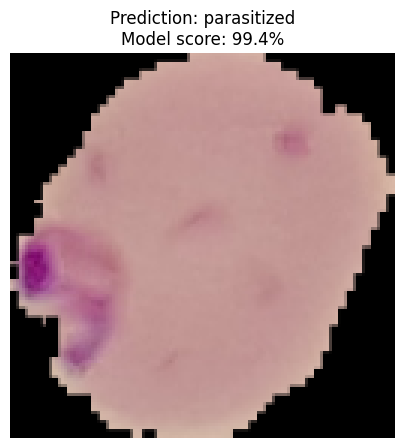

Actual class:    parasitized
Predicted class: parasitized
Model score: 99.4%
Prediction correct: True


In [ ]:
# Find one infected (parasitized) image from the test set

for images, labels in test_ds:
    for i in range(len(images)):
        actual_index = int(tf.reshape(labels[i], [-1])[0].numpy())

        if class_names[actual_index] == "parasitized":
            sample_image = images[i]
            actual_index = actual_index
            break
    else:
        continue
    break

# Make prediction
class1_score = float(
    model.predict(
        tf.expand_dims(sample_image, axis=0),
        verbose=0
    )[0][0]
)

predicted_index = 1 if class1_score >= 0.5 else 0

model_score = (
    class1_score if predicted_index == 1
    else 1.0 - class1_score
)

# Display result
plt.figure(figsize=(5, 5))
plt.imshow(sample_image.numpy().astype("uint8"))
plt.axis("off")
plt.title(
    f"Prediction: {class_names[predicted_index]}\n"
    f"Model score: {model_score:.1%}"
)
plt.show()

print("Actual class:   ", class_names[actual_index])
print("Predicted class:", class_names[predicted_index])
print(f"Model score: {model_score:.1%}")
print("Prediction correct:", actual_index == predicted_index)

## Results Summary

| Measure (test set, threshold 0.5) | Value |
|---|---|
| Accuracy | 96.37% |
| Infected recall | 95.26% |
| Infected precision | 97.39% |
| ROC-AUC | 0.988 |
| False negatives / false positives | 65 / 35 |

At the validation-selected threshold of 0.40, the secondary test evaluation achieved 96.08% accuracy, 95.55% infected recall and 96.54% infected precision. The false negatives decreased from 65 to 61, while false positives increased from 35 to 47. The results at the default threshold of 0.50 remain the primary evaluation, while the threshold of 0.40 illustrates the trade-off between detecting more infections and producing more false alarms.

## Conclusion

In this project, I developed a lightweight Convolutional Neural Network (CNN) with 101,569 parameters to classify red blood cell images as healthy or malaria-infected. On the held-out test set, the model achieved 96.37% accuracy, 95.26% recall and 97.39% precision for the infected class, with a ROC-AUC of 0.988. The training and validation curves indicate good performance, although the random data split may limit how well the results generalise to completely new patients. Grad-CAM was used to examine the image regions influencing the model's predictions, and FP16 quantization reduced the reported model-size estimate from 0.39 MB to 0.20 MB. Overall, the project demonstrates the potential of a lightweight CNN as an educational prototype for malaria-cell screening. However, the model has not been clinically validated and should not be used as a replacement for professional diagnosis.

## Limitations and Future Work

**Limitations**
- The images were split randomly and not by patient. Cells from the same patient can be in both the training and the test set, so the performance on new patients may be lower than what I report.
- I used only one dataset, with already cropped cells, and no external dataset to test the model.
- Some infected cells are still missed, mainly the ones with small or faint parasites.
- The model score is not a calibrated probability, and the model is not clinically validated.
- I did not connect a real sensor or API, and I did not try pruning.

**Future work**
- Split the data by patient and test on images from other labs and microscopes.
- Compare the model with pretrained networks such as MobileNetV2 using transfer learning.
- Add a cell segmentation step so that full slide images can be processed.
- Try more hyperparameters and calibrate the model scores.
- Connect the model to a microscope camera or hospital system through an API and test pruning.

## References
1. Rajaraman, S., Antani, S. K., Poostchi, M., et al. (2018). Pre-trained convolutional neural networks as feature extractors toward improved malaria parasite detection in thin blood smear images. PeerJ, 6, e4568.
2. TensorFlow Datasets, malaria dataset. https://www.tensorflow.org/datasets/catalog/malaria
3. Selvaraju, R. R., et al. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. ICCV.
4. TensorFlow and Keras documentation. https://www.tensorflow.org